# 01 — Les données : préparation des 4 sous-jeux C-MAPSS

Question à laquelle ce notebook répond : **« Vos données, vous les avez préparées comment ? »**

Ce notebook rassemble, sans les refaire, les cellules gardées de deux anciens notebooks (plan de
réorganisation, `docs/plan_refonte_notebooks.md`, sections 5.1 et 8.2) :

- `01_eda_preparation` (Matisse) : capteurs constants, normalisation min-max, lissage, sur FD001 ;
- `01b_sous_jeux_fd002_fd004` (Benjamin) : ce qui change dans FD002, FD003 et FD004, régimes opératoires,
  normalisation par régime, capteurs retirés sous-jeu par sous-jeu, contrôle « FD001 identique au bit près ».

**Ce qui n'est pas ici** : le gain de la normalisation par régime mesuré en validation croisée et les résultats
de l'ancien XGBoost Phase 3 sur les 4 sous-jeux (→ `evolution.ipynb`, étape 2) ; la part des moteurs test dont la
RUL vraie dépasse 125 (→ section 1 de `resultats/FD00X.ipynb`).

**Où se fait le calcul.** Tout le traitement vit dans `src/`, une seule fois : `src/preprocessing.py`
(chargement de FD001, capteurs constants, min-max, lissage), `src/features.py` (pipeline FD001 validé des
Phases 1 à 3) et `src/sous_jeux.py` (les 4 sous-jeux, régimes, normalisation par régime). Ce notebook appelle
ces fonctions ; il ne recopie pas leur code.

**Plan**

1. Les 4 sous-jeux : ce qui change de l'un à l'autre
2. FD001 : chargement et capteurs constants
3. FD001 : normalisation (min-max ou standardisation ?)
4. FD001 : lissage du signal
5. FD002 et FD004 : les régimes de vol
6. FD002 et FD004 : la normalisation par régime
7. Les capteurs retirés, sous-jeu par sous-jeu
8. Contrôle : FD001 identique au bit près au pipeline validé
9. Conclusion et limites

## Règle méthodologique (fixée avant tout résultat)

**Le jeu de test ne sert jamais à choisir** : ni la préparation, ni le modèle, ni un réglage. Les choix de ce
notebook (capteurs retirés, méthode de normalisation, nombre de régimes, fenêtre de lissage) se font sur le
**train seulement** ; le test reçoit les règles apprises sur le train (`transform` / `predict` seuls), jamais un
nouvel apprentissage.

Référence colonnes (`data/readme.txt`) : `unit_number`, `time_cycles`, `op_setting_1..3`, `sensor_1..21`
(26 colonnes, pas de ligne d'en-tête dans les fichiers source).

### Imports, noms des colonnes et réglages d'affichage

On importe les librairies et les fonctions de `src/`. Les 26 noms de colonnes du fichier NASA sont écrits en
toutes lettres **une seule fois**, dans `src/preprocessing.py` (`COLUMNS`) : le fichier brut n'a pas de ligne
d'en-tête, donc il faut les fournir nous-mêmes à pandas.

In [1]:
import sys
sys.path.insert(0, "..")  # pour pouvoir importer src/ depuis notebooks/

import matplotlib.pyplot as plt  # pour dessiner les graphiques
import numpy as np  # fonctions numeriques (egalite de tableaux dans le controle final)
import pandas as pd  # pour charger et manipuler les donnees sous forme de tableau
from sklearn.preprocessing import StandardScaler  # standardisation : seulement pour la comparaison de la section 3

# Phase 1 sur FD001 : noms des colonnes, chargement, capteurs constants, min-max, lissage
from src.preprocessing import (
    COLUMNS,
    find_constant_sensors,
    get_sensor_columns,
    lisser_capteurs,
    load_fd001,
    normalize_minmax,
)
# pipeline FD001 valide des Phases 1 a 3 (sert de reference au controle de la section 8)
from src.features import preparer_test, preparer_train
# preparation generalisee aux 4 sous-jeux
from src.sous_jeux import (
    COLONNES_REGLAGES,
    DESCRIPTION_SOUS_JEUX,
    SOUS_JEUX,
    attribuer_regimes,
    charger_rul_sous_jeu,
    charger_sous_jeu,
    choisir_nombre_regimes,
    decrire_regimes,
    normaliser_par_regime,
    preparer_sous_jeu,
    tableau_valeurs_distinctes_par_regime,
)

PLAFOND_RUL = 125  # plafond de la RUL (Phase 2) : necessaire pour appeler les fonctions de preparation

# couleurs lisibles par les daltoniens (memes que les notebooks de resultats), trois teintes pour les figures
COULEUR_1 = "#2a78d6"  # bleu
COULEUR_2 = "#eb6834"  # orange
COULEUR_TEXTE = "#52514e"  # gris fonce (reperes, annotations)
COULEURS_REGIMES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]  # une par regime
MARQUEURS_REGIMES = ["o", "s", "^", "D", "v", "P"]  # forme differente par regime : la couleur n'est pas seule
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = "#e4e3df"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

# les 26 noms de colonnes, definis une seule fois dans src/preprocessing.py
print(f"{len(COLUMNS)} colonnes : {COLUMNS}")

26 colonnes : ['unit_number', 'time_cycles', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


## 1. Les 4 sous-jeux : ce qui change de l'un à l'autre

### 1.1 Pourquoi FD001 d'abord

Le cahier des charges (section 3) constate que la quasi-totalité des projets publics observés commencent par
**FD001 seul** (1 régime, 1 mode de panne) avant d'étendre à FD002-004, et en tire la décision du projet :
*développer et valider tout le pipeline sur FD001 d'abord ; FD002-004 ne sont attaqués qu'une fois FD001 stable*.

La raison est la même que pour tout débogage : **une difficulté à la fois**. Sur FD001, si le modèle se trompe,
la cause est à chercher dans la préparation, la cible ou le modèle. Sur FD004 (6 régimes et 2 modes de panne),
une erreur pourrait aussi venir du traitement des régimes ou du mélange des pannes : on ne saurait plus quoi
corriger. C'est pourquoi les sections 2 à 4 préparent FD001, puis les sections 5 à 7 n'ajoutent que ce que
FD002, FD003 et FD004 imposent.

### 1.2 Ce qui change dans FD002, FD003 et FD004

Deux différences, annoncées par `data/readme.txt` :

- **Le nombre de régimes opératoires** (« Conditions ») : 1 pour FD001 et FD003, 6 pour FD002 et FD004
  (notion expliquée en section 5).
- **Le nombre de modes de panne** (« Fault Modes ») : un mode de panne est *le composant qui s'use*.
  FD001 et FD002 n'ont qu'un mode (dégradation du compresseur haute pression, HPC) ; FD003 et FD004 en ont deux
  (HPC ou soufflante, *Fan*). Exemple : dans FD003, le moteur 7 peut s'user par le compresseur et le moteur 8 par
  la soufflante ; les capteurs ne dérivent pas de la même façon, et **aucune colonne ne dit quel moteur a quelle
  panne** : le modèle doit apprendre les deux signatures sans étiquette. Ce point vient du readme et n'est pas
  vérifiable sur les fichiers.

Les nombres de moteurs et de lignes, eux, se **comptent** sur les fichiers. On les compare au readme :

In [2]:
# valeurs ANNONCEES par data/readme.txt (recopiees a la main du fichier, pour comparaison)
ANNONCE_README = {
    "FD001": {"moteurs_train": 100, "moteurs_test": 100, "conditions": 1, "modes_de_panne": 1},
    "FD002": {"moteurs_train": 260, "moteurs_test": 259, "conditions": 6, "modes_de_panne": 1},
    "FD003": {"moteurs_train": 100, "moteurs_test": 100, "conditions": 1, "modes_de_panne": 2},
    "FD004": {"moteurs_train": 248, "moteurs_test": 249, "conditions": 6, "modes_de_panne": 2},
}

lignes = []
for sous_jeu in SOUS_JEUX:
    train_brut = charger_sous_jeu(sous_jeu, "train")
    test_brut = charger_sous_jeu(sous_jeu, "test")
    rul_fichier = charger_rul_sous_jeu(sous_jeu)
    cycles_train = train_brut.groupby("unit_number").size()  # duree de vie complete de chaque moteur train
    cycles_test = test_brut.groupby("unit_number").size()    # longueur observee de chaque moteur test (tronquee)

    ligne = {}
    ligne["sous_jeu"] = sous_jeu
    ligne["moteurs_train (fichier)"] = train_brut["unit_number"].nunique()
    ligne["moteurs_train (readme)"] = ANNONCE_README[sous_jeu]["moteurs_train"]
    ligne["moteurs_test (fichier)"] = test_brut["unit_number"].nunique()
    ligne["moteurs_test (readme)"] = ANNONCE_README[sous_jeu]["moteurs_test"]
    ligne["lignes_RUL_FD00X"] = len(rul_fichier)
    ligne["lignes_train"] = len(train_brut)
    ligne["lignes_test"] = len(test_brut)
    ligne["duree_vie_train_mediane"] = float(cycles_train.median())
    ligne["cycles_test_observes_median"] = float(cycles_test.median())
    ligne["regimes (readme)"] = ANNONCE_README[sous_jeu]["conditions"]
    ligne["modes_de_panne (readme)"] = ANNONCE_README[sous_jeu]["modes_de_panne"]
    lignes.append(ligne)

    # les comptes ranges dans src/sous_jeux.py doivent etre ceux des fichiers
    assert ligne["moteurs_train (fichier)"] == DESCRIPTION_SOUS_JEUX[sous_jeu]["nb_moteurs_train"]
    assert ligne["moteurs_test (fichier)"] == DESCRIPTION_SOUS_JEUX[sous_jeu]["nb_moteurs_test"]
    assert ligne["lignes_RUL_FD00X"] == ligne["moteurs_test (fichier)"]

tableau_comptes = pd.DataFrame(lignes).set_index("sous_jeu")
tableau_comptes

,moteurs_train (fichier),moteurs_train (readme),moteurs_test (fichier),moteurs_test (readme),lignes_RUL_FD00X,lignes_train,lignes_test,duree_vie_train_mediane,cycles_test_observes_median,regimes (readme),modes_de_panne (readme)
sous_jeu,,,,,,,,,,,
FD001,100,100,100,100,100,20631,13096,199.0,133.5,1,1
FD002,260,260,259,259,259,53759,33991,199.0,132.0,6,1
FD003,100,100,100,100,100,24720,16596,220.5,148.0,1,2
FD004,249,248,248,249,248,61249,41214,234.0,153.5,6,2


**Lecture.** Les comptes concordent avec le readme, **sauf FD004** : le readme annonce 248 moteurs train et 249
moteurs test, les fichiers contiennent l'inverse (249 train, 248 test, et `RUL_FD004.txt` a bien 248 lignes, une
par moteur test). On utilise les comptes des fichiers. FD002 et FD004 ont environ 2,5 fois plus de moteurs que
FD001 ; leurs durées de vie médianes (199 et 234 cycles) et leurs longueurs observées en test sont du même
ordre que FD001.

## 2. FD001 : chargement et capteurs constants

### 2.1 Fonction de chargement

`load_fd001` (dans `src/preprocessing.py`) construit le chemin du fichier à partir de `DATA_DIR` (le dossier
`data/`, calculé depuis l'emplacement de `src/`, donc valable quel que soit le dossier d'où l'on lance Python) et
lit le texte brut avec pandas : séparateur « espaces de largeur variable », pas de ligne d'en-tête, noms de
colonnes `COLUMNS`. Une seule fonction pour charger `train` ou `test`, selon la valeur qu'on lui passe.

### 2.2 Chargement du fichier d'entraînement

On appelle `load_fd001` avec `"train"`, et on vérifie la taille du tableau obtenu (doit être 20 631 lignes,
26 colonnes).

In [3]:
train = load_fd001("train")  # charge le fichier d'entrainement (100 moteurs, jusqu'a la panne)
train.shape  # verifie la taille : doit etre (20631, 26)

(20631, 26)

### 2.3 Contrôle visuel

On affiche les 5 premières lignes pour vérifier que les colonnes et les valeurs ont l'air correctes avant d'aller
plus loin.

In [4]:
train.head()  # renvoie les 5 premieres lignes du tableau train (5 par defaut) : un echantillon pour verifier que tout parait correct

,unit_number,time_cycles,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


### 2.4 Capteurs à variance nulle

Un capteur constant sur l'ensemble des moteurs ne peut pas être corrélé à la dégradation (il ne varie jamais) :
on le retire.

**Attention à la précision flottante** : un test naïf `variance == 0` peut louper un capteur réellement constant
si le calcul de variance introduit une erreur d'arrondi (observé ici sur `sensor_5` et `sensor_16` : valeur
unique, mais variance calculée ≈ 1e-29 / 1e-35 au lieu de 0 exact). Le critère fiable est le nombre de valeurs
distinctes (`nunique() == 1`), pas la variance.

### 2.5 Statistiques par capteur

Pour chacun des 21 capteurs, on calcule sa variance et son nombre de valeurs distinctes, et on met les deux côte à
côte dans un tableau trié.

In [5]:
# Construit la liste des noms de colonnes capteurs (sensor_1 a sensor_21) a partir de COLUMNS :
# get_sensor_columns (src/preprocessing.py) parcourt chaque nom de colonne, dans l'ordre, et ne garde
# que ceux qui commencent par "sensor_" (boucle simple, lisible ligne par ligne dans src/)
sensor_cols = get_sensor_columns(COLUMNS)

variance_per_sensor = train[sensor_cols].var()  # variance de chaque capteur, sur tous moteurs/cycles
unique_values_per_sensor = train[sensor_cols].nunique()  # nombre de valeurs distinctes par capteur

# Met les deux statistiques cote a cote dans un seul tableau, pour pouvoir les comparer directement
sensor_summary = pd.DataFrame({
    "variance": variance_per_sensor,
    "n_unique": unique_values_per_sensor,
})
sensor_summary = sensor_summary.sort_values("n_unique")  # les capteurs a 1 seule valeur apparaissent en premier

sensor_summary  # affiche le tableau

,variance,n_unique
sensor_1,0.000000e+00,1
sensor_19,0.000000e+00,1
sensor_18,0.000000e+00,1
sensor_5,2.840037e-29,1
sensor_16,1.203765e-35,1
sensor_10,0.000000e+00,1
sensor_6,1.929279e-06,2
sensor_17,2.398667e+00,13
sensor_8,5.038938e-03,53
sensor_13,5.172330e-03,56


### 2.6 Liste finale des capteurs constants

On garde uniquement les capteurs dont `n_unique == 1` : c'est ce que fait `find_constant_sensors`
(`src/preprocessing.py`), qui parcourt les capteurs un par un et ajoute à la liste ceux qui ne prennent qu'une
seule valeur.

In [6]:
# Un capteur est reellement constant s'il ne prend qu'UNE seule valeur distincte (n_unique == 1).
# On utilise n_unique ici, pas variance == 0, a cause du probleme d'arrondi flottant explique
# ci-dessus (sensor_5 et sensor_16 sont constants mais leur variance n'est pas exactement 0)
constant_sensors = find_constant_sensors(train, sensor_cols)

constant_sensors  # affiche la liste finale des capteurs constants a retirer

['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

### 2.7 Suppression des capteurs constants

On retire maintenant les 6 capteurs identifiés ci-dessus du tableau `train`, puisqu'ils ne peuvent apporter aucune
information utile au modèle.

In [7]:
# .drop(columns=...) renvoie un NOUVEAU tableau sans ces colonnes - il ne modifie pas
# train sur place, donc on reaffecte le resultat a train pour que le changement compte
train = train.drop(columns=constant_sensors)

train.shape  # verifie la nouvelle taille : 26 - 6 = 20 colonnes restantes

(20631, 20)

### 2.8 Vérification

On recompte les colonnes capteurs restantes dans le tableau mis à jour : ça doit tomber sur 15 (21 capteurs de
départ moins les 6 retirés).

In [8]:
# On refait le meme comptage qu'en 2.5, mais sur le tableau train mis a jour
sensor_cols_restants = get_sensor_columns(train.columns)  # colonnes "sensor_..." encore presentes

len(sensor_cols_restants)  # doit valoir 15 (21 capteurs de depart - 6 retires)

15

## 3. FD001 : normalisation (min-max ou standardisation ?)

Plutôt que de choisir une méthode par convention seule, on compare deux méthodes sur nos vraies données avant de
trancher :

- **Min-max** : `(valeur - min) / (max - min)` — ramène chaque capteur entre 0 et 1. Très sensible aux valeurs
  extrêmes : une seule valeur très éloignée du reste écrase toute l'échelle et compresse le reste des valeurs dans
  un petit coin de [0, 1].
- **Standardisation (`StandardScaler`)** : `(valeur - moyenne) / écart-type` — centre chaque capteur sur 0 avec un
  écart-type de 1. Moins sensible aux valeurs extrêmes.

Critère de comparaison possible **sans modèle entraîné** : regarder si nos capteurs ont des valeurs extrêmes qui
justifieraient de préférer la standardisation, via des histogrammes avant/après. Le choix final sera revalidé en
Phase 4 avec un vrai chiffre (RMSE / score NASA), mais on peut déjà éliminer une méthode manifestement inadaptée à
nos données.

### 3.1 Deux versions indépendantes de `train`

`.copy()` crée un tableau totalement indépendant en mémoire. Sans ça, écrire `train_standard = train` ferait
pointer les deux noms vers **le même** tableau — modifier l'un modifierait l'autre aussi. On veut comparer les deux
méthodes séparément, donc on part de deux tableaux distincts : `train_standard` ci-dessous, et `train_minmax`, que
`normalize_minmax` (section 3.2) renvoie déjà sous forme de copie.

In [9]:
# copie independante, dediee a la methode standardisation
# (la version min-max est une copie fabriquee par normalize_minmax, juste en dessous)
train_standard = train.copy()

### 3.2 Application du min-max avec scikit-learn

`MinMaxScaler` apprend le minimum et le maximum de chacun des 15 capteurs avec `fit`, puis applique la
transformation avec `transform`. La méthode `fit_transform` enchaîne ces deux opérations sur les données
d'entraînement. `normalize_minmax` (`src/preprocessing.py`) fait exactement cela sur une copie du tableau, et
renvoie aussi le scaler, conservé dans `minmax_scaler` afin de pouvoir appliquer plus tard exactement la même
règle au jeu de test, sans réapprendre ses paramètres.

In [10]:
# Ici, on appelle normalize_minmax sur les 15 capteurs du train. Cet appel cree un MinMaxScaler et
# realise deux operations successives :
# 1. fit apprend les minimums et maximums uniquement a partir du train ;
# 2. transform utilise ces valeurs pour ramener les 15 capteurs entre 0 et 1.
# Il renvoie le tableau normalise (une copie : train n'est pas modifie) et le scaler entraine.
train_minmax, minmax_scaler = normalize_minmax(train, sensor_cols_restants)

train_minmax[sensor_cols_restants].describe().loc[["min", "max"]]  # verification rapide : min=0, max=1 partout

,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### 3.3 Application de la standardisation avec scikit-learn

`StandardScaler` apprend la moyenne et l'écart-type de chacun des 15 capteurs, puis centre-réduit leurs valeurs.
Cette seconde version sert ici de point de comparaison avec le min-max ; elle n'est pas retenue pour la suite du
notebook.

In [11]:
# Ici, on appelle StandardScaler() pour creer l'outil de standardisation.
standard_scaler = StandardScaler()

# Ici, on appelle standard_scaler.fit_transform() sur les 15 capteurs du train.
# Les resultats sont enregistres dans train_standard pour le graphique ci-dessous.
train_standard[sensor_cols_restants] = standard_scaler.fit_transform(
    train[sensor_cols_restants]
)

train_standard[sensor_cols_restants].describe().loc[["mean", "std", "min", "max"]]  # verification : mean≈0, std≈1

,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
mean,6.410348e-14,-1.249503e-14,9.147407e-16,-1.353687e-12,-3.159162e-14,1.008276e-12,-4.185214e-14,-2.956376e-15,3.418706e-14,3.494034e-13,-4.461841e-14,1.492240e-14,1.668851e-14,2.251034e-15,2.401470e-14
std,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00
min,-2.941625e+00,-3.177804e+00,-2.964737e+00,-7.057993e+00,-3.974497e+00,-2.770375e+00,-1.970486e+00,-2.587860e+00,-3.692663e+00,-3.005574e+00,-2.296780e+00,-3.126205e+00,-3.364479e+00,-3.741634e+00,-3.653688e+00
max,3.697829e+00,4.303846e+00,3.617202e+00,1.416833e-01,3.041891e+00,6.527526e+00,8.121740e+00,3.702368e+00,2.666353e+00,6.449748e+00,7.861686e+00,3.803699e+00,4.383828e+00,3.395609e+00,3.036489e+00


### 3.4 Comparaison visuelle

On trace, pour deux capteurs (`sensor_9`, la plus grande variance brute, et `sensor_11`, une variance plus
modeste), l'histogramme des valeurs brutes puis des deux versions normalisées — pour voir si l'une des deux
méthodes écrase visiblement les données à cause d'une valeur extrême.

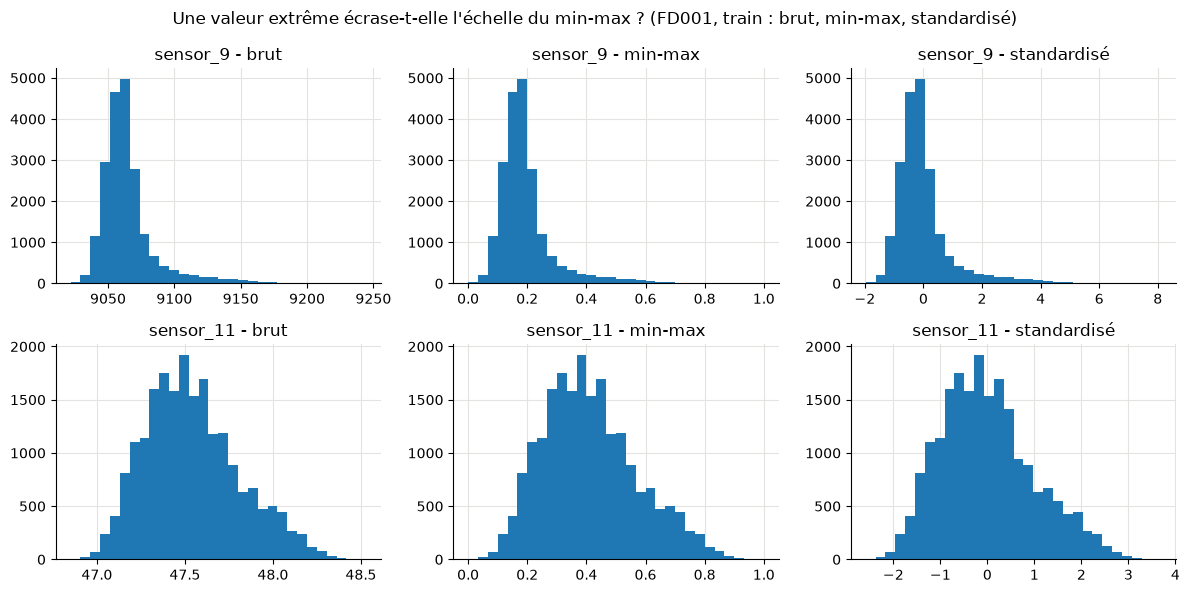

In [12]:
capteurs_a_comparer = ["sensor_9", "sensor_11"]  # les deux capteurs qu'on affiche

fig, axes = plt.subplots(2, 3, figsize=(12, 6))  # grille 2 lignes (1 par capteur) x 3 colonnes (1 par version)

for i, sensor_name in enumerate(capteurs_a_comparer):  # on parcourt les 2 capteurs, i = 0 puis 1
    axes[i, 0].hist(train[sensor_name], bins=30)  # histogramme des valeurs brutes
    axes[i, 0].set_title(f"{sensor_name} - brut")

    # train_minmax contient les valeurs deja calculees par normalize_minmax plus haut.
    axes[i, 1].hist(train_minmax[sensor_name], bins=30)  # ici, on trace ces valeurs ; on ne rappelle pas le scaler
    axes[i, 1].set_title(f"{sensor_name} - min-max")

    # train_standard contient les valeurs deja calculees par StandardScaler plus haut.
    axes[i, 2].hist(train_standard[sensor_name], bins=30)  # ici, on trace ces valeurs ; on ne rappelle pas le scaler
    axes[i, 2].set_title(f"{sensor_name} - standardisé")

# titre de la figure : la question a laquelle elle repond
fig.suptitle("Une valeur extrême écrase-t-elle l'échelle du min-max ? (FD001, train : brut, min-max, standardisé)")
plt.tight_layout()  # evite que les titres se chevauchent
plt.show()  # affiche la figure

### 3.5 Décision finale : on retient le min-max

Justification complète dans `docs/01_eda_preparation.md`. En résumé : coût nul pour les modèles à arbres de la
Phase 3, entrées bornées adaptées au LSTM prévu ensuite, hypothèse de distribution gaussienne de la standardisation
de toute façon mise à mal par nos données (`sensor_9` très asymétrique), convention déjà établie sur ce dataset.
`train_standard` est gardé au-dessus seulement comme référence de comparaison, pas réutilisé pour la suite.

On garde aussi une copie `train_avant_lissage`, prise ici avant le lissage — **important** : sans un nouveau
`.copy()`, cette copie pointerait vers le même tableau que `train` et se retrouverait modifiée si le lissage
travaillait sur place (même piège qu'en 3.1), ce qui empêcherait toute comparaison avant/après plus bas.
`lisser_capteurs` renvoie de toute façon une copie ; la copie explicite garde la comparaison indépendante de ce
détail.

In [13]:
train = train_minmax  # on continue avec la version min-max pour la suite du notebook
train_avant_lissage = train.copy()  # copie a part, gelee ici, uniquement pour comparer avant/apres lissage

## 4. FD001 : lissage du signal

Les capteurs contiennent du bruit de mesure cycle-à-cycle, en plus du vrai signal de dégradation (ex. `sensor_2` :
641.82 → 642.15 → 642.35 → 642.35 → 642.37 sur les 5 premiers cycles du moteur 1 — cette gigue n'est pas de la
dégradation). Le lissage atténue ce bruit pour que le modèle voie mieux la tendance réelle.

**Deux règles de correction à respecter, quelle que soit la méthode** :
1. **Causalité** : le lissage du cycle `t` ne doit utiliser que des cycles `≤ t` (passé), jamais de cycles futurs —
   sur le jeu de test, on n'a par définition pas accès au futur d'un moteur en cours de vie.
2. **Par moteur, jamais à travers deux moteurs différents** : `train` empile les 100 moteurs les uns après les
   autres ; un lissage naïf sur toute la colonne mélangerait la fin d'un moteur avec le début du suivant.

**Méthode retenue** : moyenne mobile, fenêtre de 5 cycles (cohérent avec le benchmark exploratoire documenté dans
le README). Simple à justifier, et `pandas.rolling()` est causal par défaut (ne regarde que le passé).

### 4.1 Application de la moyenne mobile, moteur par moteur

`lisser_capteurs` (`src/preprocessing.py`) fait, pour chaque capteur, une boucle sur les moteurs :
`train["unit_number"].unique()` renvoie la liste des identifiants de moteurs distincts (1 à 100). Pour chaque
moteur, `train["unit_number"] == moteur_id` crée une colonne de Vrai/Faux (Vrai sur les lignes de ce moteur) ;
`train.loc[masque, sensor_name]` sélectionne uniquement ces lignes. `.rolling(5, min_periods=1).mean()` moyenne
chaque valeur avec ses 4 précédentes (seulement dans cette sélection, donc jamais avec un autre moteur) ;
`min_periods=1` évite des cases vides sur les tout premiers cycles de chaque moteur, où 5 cycles ne sont pas encore
disponibles.

In [14]:
FENETRE_LISSAGE = 5  # nombre de cycles utilises pour la moyenne mobile

# lisser_capteurs lisse chaque capteur, un par un, et chaque moteur separement :
# rolling() ne regarde que les lignes d'un seul moteur (jamais de fuite entre deux moteurs)
# et jamais de cycle futur (rolling est causal par defaut). Il renvoie une copie lissee.
train = lisser_capteurs(train, sensor_cols_restants, fenetre=FENETRE_LISSAGE)

train[sensor_cols_restants].head()  # apercu du resultat

,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,0.183735,0.406802,0.309757,1.0,0.726248,0.242424,0.109755,0.369048,0.633262,0.205882,0.199608,0.363986,0.333333,0.713178,0.724662
1,0.233434,0.429911,0.331195,1.0,0.677134,0.227273,0.104999,0.375000,0.699360,0.242647,0.181211,0.387649,0.333333,0.689922,0.727838
2,0.270080,0.409781,0.344306,1.0,0.688137,0.242424,0.116680,0.333333,0.731343,0.235294,0.178071,0.377581,0.277778,0.669251,0.692350
3,0.288404,0.371376,0.341028,1.0,0.701288,0.261364,0.118640,0.291667,0.770789,0.250000,0.177276,0.324836,0.291667,0.645349,0.684859
4,0.300602,0.348594,0.353747,1.0,0.694686,0.257576,0.124904,0.284524,0.765885,0.247059,0.176767,0.340285,0.316667,0.634109,0.688788


### 4.2 Vérification visuelle

On trace `sensor_11`, brut vs lissé, sur les cycles du moteur 1 seul (en utilisant `train_avant_lissage` pour le
« avant », justement pour éviter le piège décrit en 3.5) — le lissé doit suivre la même tendance que le brut mais
avec moins de gigue cycle-à-cycle.

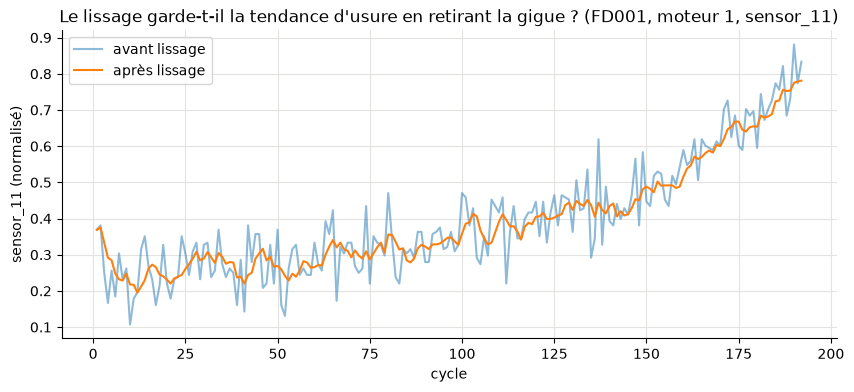

In [15]:
masque_moteur_1 = train["unit_number"] == 1  # Vrai uniquement sur les lignes du moteur 1
cycles_moteur_1 = train.loc[masque_moteur_1, "time_cycles"]  # numeros de cycle du moteur 1

plt.figure(figsize=(10, 4))
plt.plot(cycles_moteur_1, train_avant_lissage.loc[masque_moteur_1, "sensor_11"], label="avant lissage", alpha=0.5)
plt.plot(cycles_moteur_1, train.loc[masque_moteur_1, "sensor_11"], label="après lissage")
plt.xlabel("cycle")
plt.ylabel("sensor_11 (normalisé)")
# titre : la question a laquelle la figure repond
plt.title("Le lissage garde-t-il la tendance d'usure en retirant la gigue ? (FD001, moteur 1, sensor_11)")
plt.legend()
plt.show()

## 5. FD002 et FD004 : les régimes de vol

### 5.1 La notion

Un **régime opératoire** est une condition de vol : à quelle altitude, à quelle vitesse et avec quelle poussée
le moteur tourne pendant le cycle enregistré. Exemple concret : un moteur **neuf** au décollage, au niveau de la
mer, et le **même moteur** en croisière à 42 000 pieds n'ont pas du tout la même température ni la même pression
en sortie de compresseur. Si on ne tient pas compte du régime, un saut de capteur peut faire croire à de l'usure
alors que l'avion a seulement changé d'altitude.

Les trois réglages opératoires (`op_setting_1` à `op_setting_3`) décrivent ce régime. Le readme ne les nomme
pas. Saxena et al. (2008, p. 6 du PDF `data/Damage Propagation Modeling.pdf`) décrivent, pour le jeu de données du
challenge PHM08, six conditions de vol définies par l'altitude (0 à 42 000 pieds), le nombre de Mach (0 à 0,84)
et le TRA, l'angle de la manette des gaz (20 à 100). Les plages observées dans FD002 (ci-dessous) sont
compatibles avec cette lecture ; on garde néanmoins les noms neutres « réglage 1, 2, 3 ».

In [16]:
lignes = []
for sous_jeu in SOUS_JEUX:
    train_brut = charger_sous_jeu(sous_jeu, "train")
    for colonne in COLONNES_REGLAGES:  # un reglage a la fois
        ligne = {}
        ligne["sous_jeu"] = sous_jeu
        ligne["reglage"] = colonne
        ligne["min"] = train_brut[colonne].min()
        ligne["max"] = train_brut[colonne].max()
        ligne["ecart_type"] = train_brut[colonne].std()
        ligne["nb_valeurs_distinctes"] = train_brut[colonne].nunique()
        lignes.append(ligne)
pd.DataFrame(lignes).set_index(["sous_jeu", "reglage"]).round(4)

min       max  ecart_type  nb_valeurs_distinctes
sous_jeu reglage                                                            
FD001    op_setting_1   -0.0087    0.0087      0.0022                    158
         op_setting_2   -0.0006    0.0006      0.0003                     13
         op_setting_3  100.0000  100.0000      0.0000                      1
FD002    op_setting_1    0.0000   42.0080     14.7474                    536
         op_setting_2    0.0000    0.8420      0.3100                    105
         op_setting_3   60.0000  100.0000     14.2377                      2
FD003    op_setting_1   -0.0086    0.0086      0.0022                    160
         op_setting_2   -0.0006    0.0007      0.0003                     14
         op_setting_3  100.0000  100.0000      0.0000                      1
FD004    op_setting_1    0.0000   42.0080     14.7807                    536
         op_setting_2    0.0000    0.8420      0.3107                    105
         op_setting_3   60.0000  100.0000     14.2520                      2

**Lecture.** Dans FD001 et FD003, les réglages ne bougent presque pas (réglage 1 entre −0,009 et +0,009,
réglage 3 toujours égal à 100) : c'est du bruit autour d'un seul régime. Dans FD002 et FD004, le réglage 1 va de 0
à 42, le réglage 2 de 0 à 0,84 et le réglage 3 ne prend que deux valeurs (60 et 100) : il y a plusieurs régimes.
Combien exactement ? On ne le recopie pas du readme : on le **mesure**.

### 5.2 Regrouper automatiquement : le K-Means

Le **K-Means** range des points en *k* groupes en répétant deux étapes jusqu'à stabilité : (1) chaque point
rejoint le centre le plus proche, (2) chaque centre se déplace à la moyenne de ses points. Exemple à une dimension
avec k = 2 et les points 0 ; 0,1 ; 10 ; 10,2 : on obtient les groupes {0 ; 0,1} (centre 0,05) et {10 ; 10,2}
(centre 10,1). Ici, chaque point est une ligne du fichier décrite par ses 3 réglages.

Deux règles : le K-Means est **appris sur le train seulement** (`fit`) ; le test reçoit son régime par
`predict` (le centre appris le plus proche), jamais par un nouvel apprentissage — sinon le test participerait
à la définition des régimes (fuite d'information). Graine fixée (`random_state=42`) et 10 initialisations
(`n_init=10`, K-Means garde la meilleure) pour obtenir les mêmes régimes à chaque exécution.

### 5.3 Combien de groupes ? Inertie et silhouette

On essaie k = 2 à 10 sur le train :

- **inertie** : somme des distances au carré de chaque point au centre de son groupe. Elle baisse toujours quand
  k augmente ; on cherche un « coude » (le k après lequel elle ne baisse presque plus) ;
- **silhouette** (entre −1 et 1) : pour chaque point, compare sa distance moyenne aux points de son groupe et
  au groupe voisin le plus proche. Proche de 1 = groupes compacts et bien séparés ; elle est maximale pour le
  bon k. Calculée sur 5 000 points tirés avec une graine fixe (le calcul exact compare toutes les paires de
  50 000 points : trop long).

In [17]:
choix_k = {}  # sous-jeu -> tableau (k, inertie, silhouette)
for sous_jeu in ["FD002", "FD004"]:
    train_brut = charger_sous_jeu(sous_jeu, "train")
    choix_k[sous_jeu] = choisir_nombre_regimes(train_brut[COLONNES_REGLAGES], valeurs_k=list(range(2, 11)))

tableau_k = pd.concat([choix_k["FD002"].set_index("k"), choix_k["FD004"].set_index("k")], axis=1,
                      keys=["FD002", "FD004"])
tableau_k.round(4)

FD002                    FD004           
         inertie silhouette       inertie silhouette
k                                                   
2   1.168722e+07     0.6467  1.337591e+07     0.6504
3   1.865414e+06     0.8018  2.116834e+06     0.8035
4   6.504276e+05     0.8120  7.402168e+05     0.8274
5   2.465613e+05     0.9252  2.814402e+05     0.9269
6   4.107000e-01     0.9997  4.684000e-01     0.9997
7   3.255000e-01     0.8962  3.714000e-01     0.8976
8   2.739000e-01     0.8357  3.124000e-01     0.8361
9   2.241000e-01     0.7699  2.564000e-01     0.7720
10  1.753000e-01     0.7068  2.003000e-01     0.7056

Le k retenu est celui qui maximise la silhouette ; on vérifie qu'il est égal au nombre de régimes du readme
(sinon la cellule s'arrête sur une erreur) :

In [18]:
for sous_jeu in ["FD002", "FD004"]:
    tableau = choix_k[sous_jeu]
    meilleur_k = int(tableau.loc[tableau["silhouette"].idxmax(), "k"])
    print(f"{sous_jeu} : silhouette maximale pour k = {meilleur_k} "
          f"({tableau['silhouette'].max():.4f}) ; nombre de regimes du readme : {DESCRIPTION_SOUS_JEUX[sous_jeu]['nb_regimes']}")
    assert meilleur_k == DESCRIPTION_SOUS_JEUX[sous_jeu]["nb_regimes"]

FD002 : silhouette maximale pour k = 6 (0.9997) ; nombre de regimes du readme : 6
FD004 : silhouette maximale pour k = 6 (0.9997) ; nombre de regimes du readme : 6


**Lecture.** Pour FD002 comme pour FD004, la silhouette culmine à k = 6 (0,9997, presque le maximum théorique
de 1), et l'inertie s'effondre entre k = 5 (environ 247 000 pour FD002, 281 000 pour FD004) et k = 6 (moins de 1) :
six groupes très serrés et très éloignés les uns des autres. Les données confirment le readme ; `src/sous_jeux.py`
utilise donc `n_clusters = 6` pour ces deux sous-jeux.

### 5.4 Figure : les six régimes

On prépare les 4 sous-jeux avec `preparer_sous_jeu` (préparation par défaut ; pour FD002 et FD004, K-Means appris
sur le train), puis on dessine les réglages du train de FD002 et FD004, une couleur **et** une forme de marqueur
par régime, avec le numéro du régime écrit à côté de chaque groupe. Les contextes de FD001 et FD003 servent aux
sections 7 et 8.

In [19]:
contextes = {}  # sous-jeu -> contexte de preparation (preparation par defaut de src/sous_jeux.py)
for sous_jeu in SOUS_JEUX:
    contextes[sous_jeu] = preparer_sous_jeu(sous_jeu, fenetre=5, plafond=PLAFOND_RUL)

for sous_jeu in ["FD002", "FD004"]:
    print(f"=== {sous_jeu} : centres des regimes (appris sur le train) et nombre de lignes ===")
    print(decrire_regimes(contextes[sous_jeu]).round(3).to_string(index=False))

=== FD002 : centres des regimes (appris sur le train) et nombre de lignes ===
 regime  op_setting_1  op_setting_2  op_setting_3  nb_lignes_train  nb_lignes_test
      0        42.003         0.840         100.0            13458            8483
      1        20.003         0.701         100.0             8122            5063
      2        25.003         0.621          60.0             8002            5042
      3         0.002         0.000         100.0             8044            5148
      4        10.003         0.250         100.0             8096            5107
      5        35.003         0.841         100.0             8037            5148
=== FD004 : centres des regimes (appris sur le train) et nombre de lignes ===
 regime  op_setting_1  op_setting_2  op_setting_3  nb_lignes_train  nb_lignes_test
      0        42.003         0.840         100.0            15395           10382
      1        10.003         0.251         100.0             9224            6185
      2       

La figure : colonnes 1 et 2, les réglages du train (une couleur et une forme par régime, numéro écrit à côté du
centre) ; colonne 3, la silhouette en fonction de k.

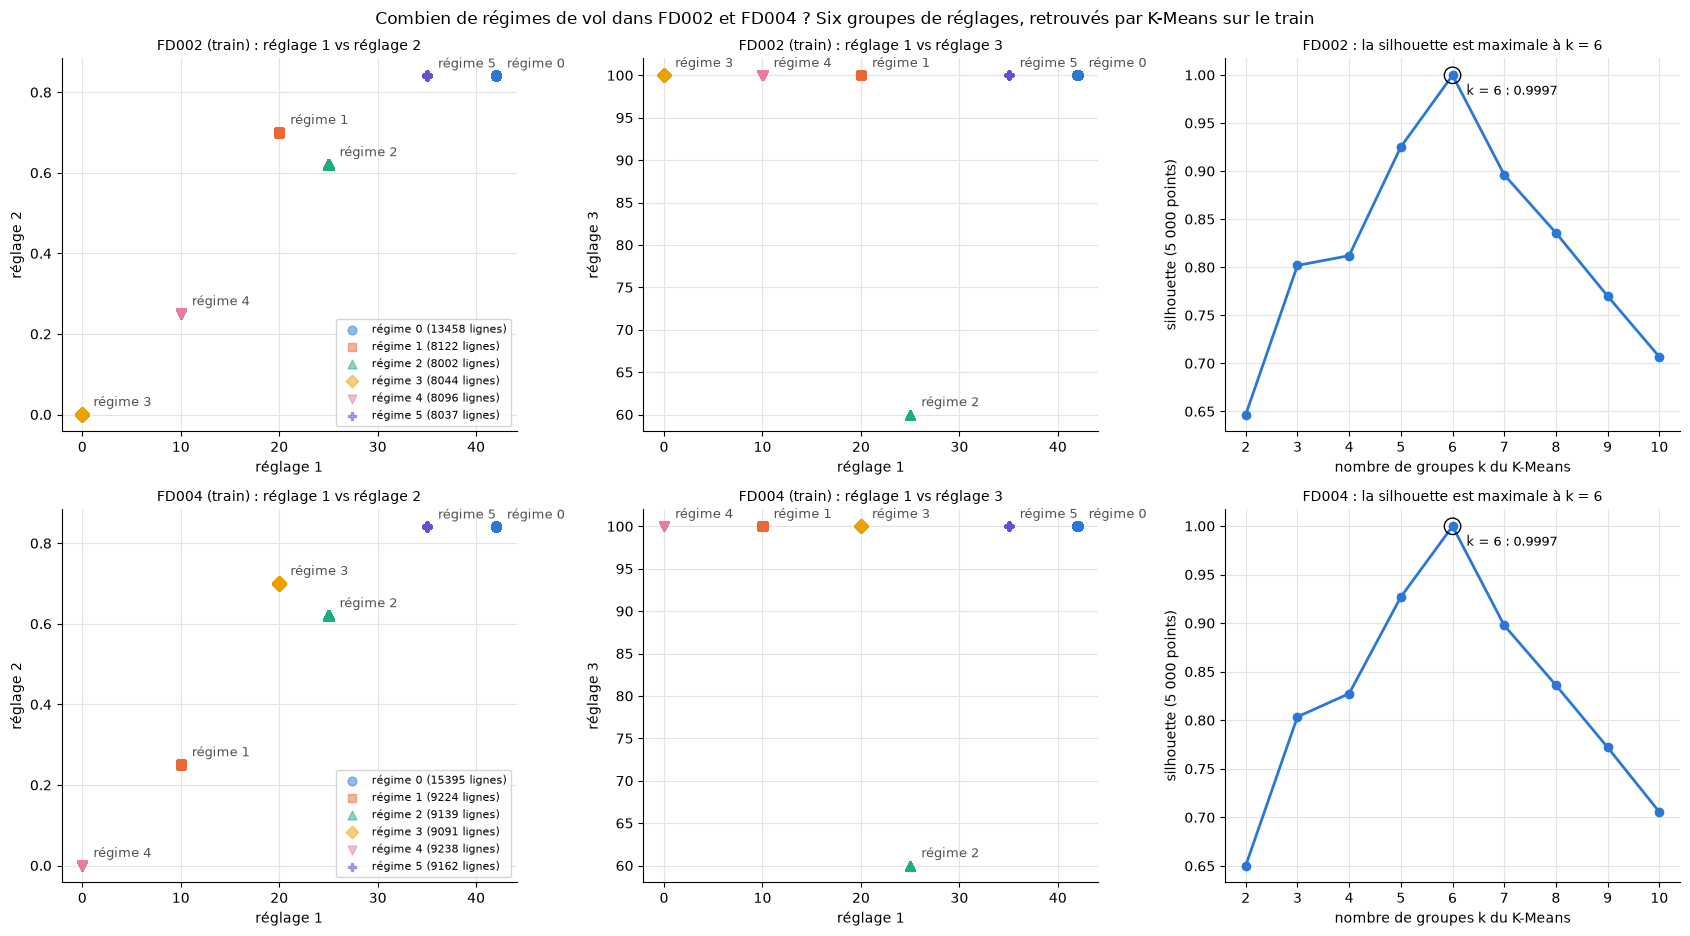

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
paires_reglages = [("op_setting_1", "op_setting_2", "réglage 2"), ("op_setting_1", "op_setting_3", "réglage 3")]

for numero_ligne, sous_jeu in enumerate(["FD002", "FD004"]):
    train_sous_jeu = contextes[sous_jeu]["train"]  # train prepare du sous-jeu, avec la colonne "regime"
    centres = contextes[sous_jeu]["kmeans"].cluster_centers_
    for numero_colonne, (colonne_x, colonne_y, nom_y) in enumerate(paires_reglages):
        ax = axes[numero_ligne, numero_colonne]
        for regime in range(6):  # un regime a la fois : couleur ET marqueur propres
            lignes_regime = train_sous_jeu[train_sous_jeu["regime"] == regime]
            ax.scatter(lignes_regime[colonne_x], lignes_regime[colonne_y], s=40, alpha=0.5,
                       color=COULEURS_REGIMES[regime], marker=MARQUEURS_REGIMES[regime],
                       label=f"régime {regime} ({len(lignes_regime)} lignes)")
            # etiquette directe a cote du centre du groupe
            position_x = centres[regime, COLONNES_REGLAGES.index(colonne_x)]
            position_y = centres[regime, COLONNES_REGLAGES.index(colonne_y)]
            ax.annotate(f"régime {regime}", (position_x, position_y), xytext=(8, 6), textcoords="offset points",
                        fontsize=9, color=COULEUR_TEXTE)
        ax.set_xlabel("réglage 1")
        ax.set_ylabel(nom_y)
        ax.set_title(f"{sous_jeu} (train) : réglage 1 vs {nom_y}", fontsize=10)
    axes[numero_ligne, 0].legend(fontsize=8, loc="lower right")

    # 3e colonne : la silhouette en fonction de k
    ax = axes[numero_ligne, 2]
    tableau = choix_k[sous_jeu]
    ax.plot(tableau["k"], tableau["silhouette"], marker="o", color=COULEUR_1, linewidth=2)
    meilleure = tableau.loc[tableau["silhouette"].idxmax()]
    ax.scatter([meilleure["k"]], [meilleure["silhouette"]], s=140, facecolors="none", edgecolors="black", zorder=3)
    ax.annotate(f"k = {int(meilleure['k'])} : {meilleure['silhouette']:.4f}", (meilleure["k"], meilleure["silhouette"]),
                xytext=(10, -14), textcoords="offset points", fontsize=9)
    ax.set_xlabel("nombre de groupes k du K-Means")
    ax.set_ylabel("silhouette (5 000 points)")
    ax.set_title(f"{sous_jeu} : la silhouette est maximale à k = {int(meilleure['k'])}", fontsize=10)

# titre de la figure : la question a laquelle elle repond
fig.suptitle("Combien de régimes de vol dans FD002 et FD004 ? Six groupes de réglages, retrouvés par K-Means sur le train")
plt.tight_layout()
plt.show()

**Lecture.** Chaque régime est un amas minuscule (l'écart-type du réglage 1 à l'intérieur d'un régime est
d'environ 0,003, pour des centres voisins espacés de 5 à 10 unités) : les points d'un même régime se superposent. Les
centres sont les mêmes dans FD002 et FD004 (réglage 1 ≈ 0, 10, 20, 25, 35, 42), mais les **numéros** de régime
diffèrent d'un sous-jeu à l'autre (le K-Means numérote ses groupes dans un ordre arbitraire) : « régime 3 » de
FD002 n'est pas « régime 3 » de FD004. Le régime 25 / 0,62 / 60 est le seul à réglage 3 = 60.

Dernier contrôle : chaque régime du train est aussi présent dans le test (dernière colonne du tableau des centres,
« nb_lignes_test »), donc aucun moteur test ne tombe dans un régime sans scaler appris.

## 6. FD002 et FD004 : la normalisation par régime

### 6.1 Pourquoi la normalisation de FD001 ne suffit plus

En section 3, chaque capteur de FD001 est ramené entre 0 et 1 avec son minimum et son maximum sur tout le train
(min-max). Sur FD002, le niveau d'un capteur dépend d'abord du régime. Le tableau ci-dessous donne, pour trois
capteurs, la moyenne, le minimum et le maximum **dans chaque régime** du train de FD002 :

In [21]:
train_fd002_brut = charger_sous_jeu("FD002", "train")
train_fd002_brut["regime"] = attribuer_regimes(train_fd002_brut, contextes["FD002"]["kmeans"])  # predict seul
train_fd002_brut.groupby("regime")[["sensor_2", "sensor_11", "sensor_4"]].agg(["mean", "min", "max"]).round(2)

sensor_2                 sensor_11               sensor_4                  
           mean     min     max      mean    min    max     mean      min      max
regime                                                                            
0        549.70  548.25  551.35     42.15  41.50  43.03  1127.80  1105.27  1155.57
1        607.56  606.11  609.23     44.45  43.80  45.37  1253.12  1229.74  1283.77
2        536.87  535.53  538.15     36.80  36.23  37.55  1050.32  1023.77  1075.23
3        642.68  641.24  644.52     47.54  46.90  48.51  1408.86  1384.49  1439.23
4        604.91  603.21  606.45     45.49  44.85  46.35  1311.25  1287.71  1338.99
5        555.80  554.32  557.39     41.98  41.38  42.76  1131.53  1111.62  1157.25

**Lecture.** `sensor_11` vaut en moyenne 36,80 dans le régime 2 et 47,54 dans le régime 3 : un saut d'environ
11 unités, alors qu'**à l'intérieur** d'un régime, toute la vie des moteurs (du neuf à la panne) tient dans une
plage d'environ 1 à 2 unités. Avec un min-max global, la valeur normalisée dirait surtout « dans quel régime vole
l'avion », et très peu « à quel point le moteur est usé ».

**La normalisation conditionnelle** apprend **un min-max par régime**, sur les seules lignes de ce régime dans le
train : 0 = la plus petite valeur observée dans ce régime, 1 = la plus grande. Exemple : dans le régime 2, une
lecture de `sensor_11` à mi-chemin entre le min et le max du régime 2 donne 0,5 ; dans le régime 3, une lecture à
mi-chemin entre le min et le max du régime 3 donne aussi 0,5, alors que les valeurs brutes diffèrent de 11 unités.
Les valeurs de régimes différents deviennent comparables. Le test applique les scalers du train (`transform`
seul), jamais un nouvel apprentissage.

### 6.2 Pourquoi normaliser AVANT de lisser

Le lissage (moyenne mobile sur 5 cycles, section 4) fait la moyenne de cycles consécutifs. Or dans FD002, le régime
change presque à chaque cycle. Les cinq premiers cycles du moteur 1 :

In [22]:
cinq_cycles_bruts = train_fd002_brut[train_fd002_brut["unit_number"] == 1].head(5)  # 5 premiers cycles du moteur 1
# normalisation par regime (scalers du train, transform seul) : les scalers attendent les 17 capteurs gardes
cinq_cycles_normalises = normaliser_par_regime(cinq_cycles_bruts, contextes["FD002"]["capteurs"],
                                               contextes["FD002"]["scalers"])

cinq_cycles = pd.DataFrame()
cinq_cycles["time_cycles"] = cinq_cycles_bruts["time_cycles"]
cinq_cycles["regime"] = cinq_cycles_bruts["regime"]
cinq_cycles["op_setting_1"] = cinq_cycles_bruts["op_setting_1"]
cinq_cycles["op_setting_3"] = cinq_cycles_bruts["op_setting_3"]
cinq_cycles["sensor_11_brut"] = cinq_cycles_bruts["sensor_11"]
cinq_cycles["sensor_11_normalise_par_regime"] = cinq_cycles_normalises["sensor_11"]
print(cinq_cycles.round(3).to_string(index=False))
print(f"\nMoyenne des 5 valeurs brutes : {cinq_cycles['sensor_11_brut'].mean():.2f} "
      f"(une valeur qui ne correspond a aucun regime)")
print(f"Moyenne des 5 valeurs normalisees par regime : {cinq_cycles['sensor_11_normalise_par_regime'].mean():.3f}")

 time_cycles  regime  op_setting_1  op_setting_3  sensor_11_brut  sensor_11_normalise_par_regime
           1       5        34.998         100.0           42.02                           0.464
           2       0        41.998         100.0           42.20                           0.458
           3       2        24.999          60.0           36.69                           0.348
           4       0        42.008         100.0           41.96                           0.301
           5       2        25.000          60.0           36.89                           0.500

Moyenne des 5 valeurs brutes : 39.95 (une valeur qui ne correspond a aucun regime)
Moyenne des 5 valeurs normalisees par regime : 0.414


**Lecture.** La moyenne des cinq valeurs brutes (39,95) mélange des cycles des régimes 5, 0 et 2 : elle ne
correspond à aucun régime, et elle monterait ou descendrait selon le nombre de cycles du régime 2 tombés dans la
fenêtre, sans aucun lien avec l'usure. Une fois les valeurs normalisées par régime, les cinq cycles sont sur la même
échelle et la moyenne mobile ne lisse plus que le bruit de mesure. D'où l'ordre de `src/sous_jeux.py` :
**régime → normalisation par régime → lissage et features glissantes, moteur par moteur.**

### 6.3 Figure avant / après sur un moteur de FD002

Moteur 1 du train de FD002 (suivi jusqu'à sa panne), capteur `sensor_11` : (1) valeurs brutes, une couleur et une
forme par régime ; (2) méthode FD001 appliquée telle quelle (min-max global puis lissage) ; (3) normalisation par
régime puis lissage (la préparation retenue).

In [23]:
CAPTEUR_FIGURE = "sensor_11"
MOTEUR_FIGURE = 1

# (1) brut : le train brut, avec le regime de chaque cycle
moteur_brut = train_fd002_brut[train_fd002_brut["unit_number"] == MOTEUR_FIGURE]

# (2) methode FD001 telle quelle : min-max global appris sur tout le train, puis lissage
contexte_fd002_global = preparer_sous_jeu("FD002", fenetre=5, plafond=PLAFOND_RUL, normalisation="globale")
scaler_global = contexte_fd002_global["scalers"][0]  # le meme scaler pour tous les regimes
valeurs_globales = scaler_global.transform(moteur_brut[contexte_fd002_global["capteurs"]])  # transform seul
position_capteur = contexte_fd002_global["capteurs"].index(CAPTEUR_FIGURE)
moteur_global_points = valeurs_globales[:, position_capteur]
moteur_global_lisse = contexte_fd002_global["train"].loc[moteur_brut.index, CAPTEUR_FIGURE]

# (3) normalisation par regime, puis lissage (preparation par defaut de FD002)
# le scaler de chaque regime a ete appris sur les 17 capteurs gardes : on lui donne les 17, puis on garde sensor_11
moteur_normalise = normaliser_par_regime(moteur_brut, contextes["FD002"]["capteurs"], contextes["FD002"]["scalers"])
moteur_par_regime_points = moteur_normalise[CAPTEUR_FIGURE]
moteur_par_regime_lisse = contextes["FD002"]["train"].loc[moteur_brut.index, CAPTEUR_FIGURE]
duree_vie = int(moteur_brut["time_cycles"].max())
print(f"Moteur {MOTEUR_FIGURE} de FD002 : {duree_vie} cycles jusqu'a la panne")

Moteur 1 de FD002 : 149 cycles jusqu'a la panne


La figure, trois panneaux superposés sur le même axe des cycles :

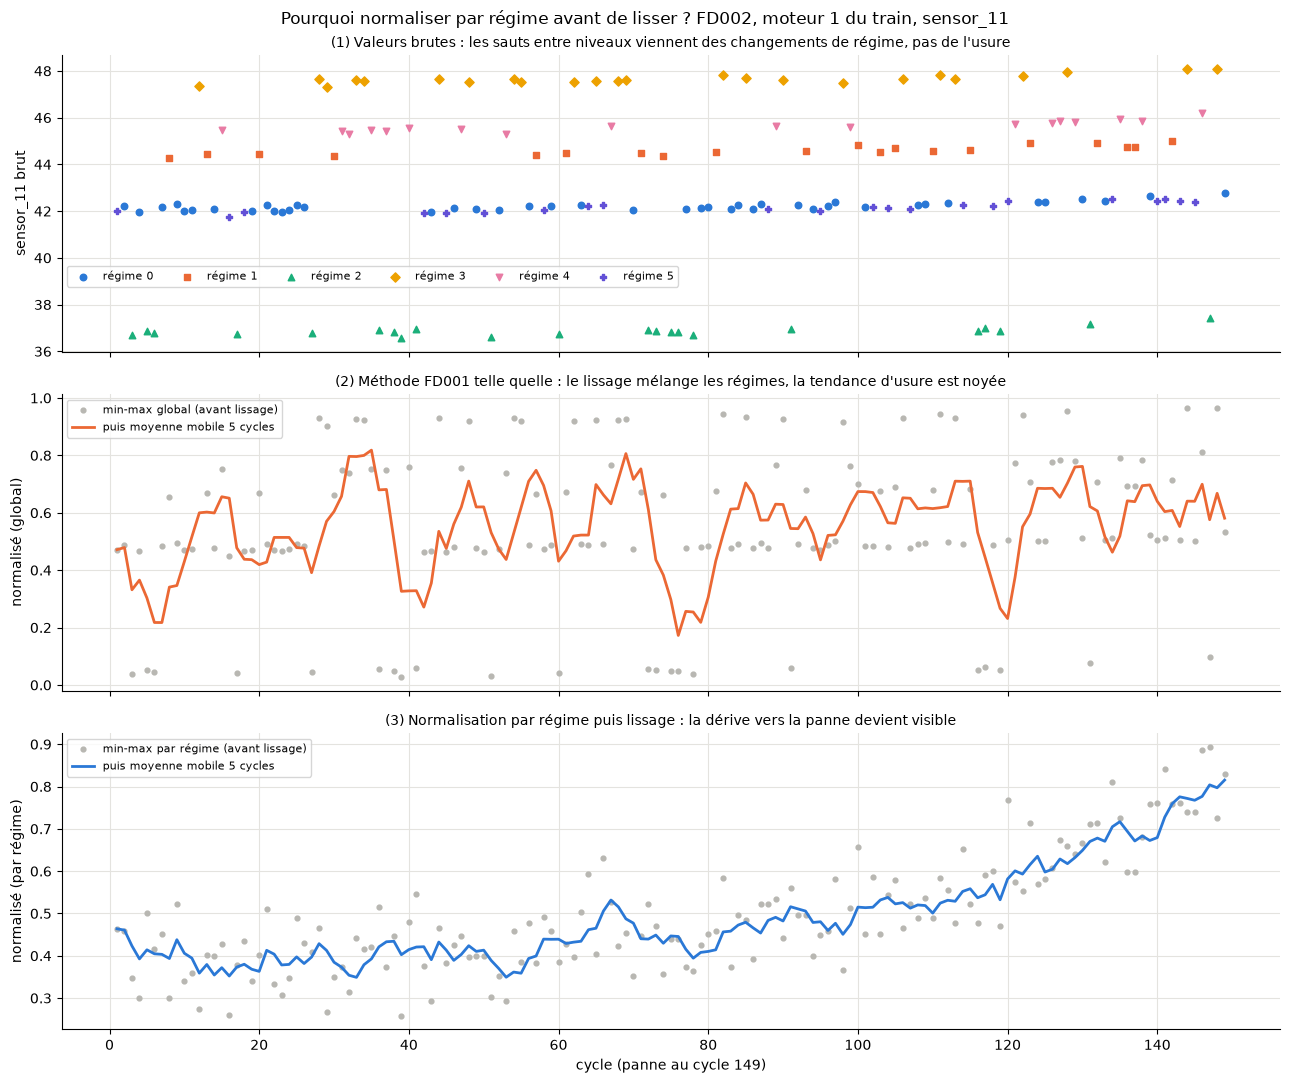

In [24]:
fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
cycles = moteur_brut["time_cycles"]

# (1) brut, une couleur et une forme par regime
ax = axes[0]
for regime in range(6):
    masque = moteur_brut["regime"] == regime
    ax.scatter(cycles[masque], moteur_brut.loc[masque, CAPTEUR_FIGURE], s=22, color=COULEURS_REGIMES[regime],
               marker=MARQUEURS_REGIMES[regime], label=f"régime {regime}")
ax.set_ylabel(f"{CAPTEUR_FIGURE} brut")
ax.set_title("(1) Valeurs brutes : les sauts entre niveaux viennent des changements de régime, pas de l'usure", fontsize=10)
ax.legend(fontsize=8, ncol=6, loc="lower left", bbox_to_anchor=(0.0, 0.2))  # dans la bande vide entre les niveaux

# (2) min-max global (methode FD001) puis lissage
ax = axes[1]
ax.scatter(cycles, moteur_global_points, s=12, color="#b8b7b2", label="min-max global (avant lissage)")
ax.plot(cycles, moteur_global_lisse, color=COULEUR_2, linewidth=2, label="puis moyenne mobile 5 cycles")
ax.set_ylabel("normalisé (global)")
ax.set_title("(2) Méthode FD001 telle quelle : le lissage mélange les régimes, la tendance d'usure est noyée", fontsize=10)
ax.legend(fontsize=8, loc="upper left")

# (3) normalisation par regime puis lissage
ax = axes[2]
ax.scatter(cycles, moteur_par_regime_points, s=12, color="#b8b7b2", label="min-max par régime (avant lissage)")
ax.plot(cycles, moteur_par_regime_lisse, color=COULEUR_1, linewidth=2, label="puis moyenne mobile 5 cycles")
ax.set_ylabel("normalisé (par régime)")
ax.set_xlabel(f"cycle (panne au cycle {duree_vie})")
ax.set_title("(3) Normalisation par régime puis lissage : la dérive vers la panne devient visible", fontsize=10)
ax.legend(fontsize=8, loc="upper left")

# titre de la figure : la question a laquelle elle repond
fig.suptitle(f"Pourquoi normaliser par régime avant de lisser ? FD002, moteur {MOTEUR_FIGURE} du train, {CAPTEUR_FIGURE}")
plt.tight_layout()
plt.show()

**Lecture.** En (1), les valeurs brutes forment six bandes horizontales, une par régime : l'usure est invisible à
cette échelle. En (2), le min-max global ne fait que changer l'échelle : la moyenne mobile oscille selon les
régimes tombés dans la fenêtre. En (3), chaque cycle est ramené à l'échelle de son régime : la courbe lissée monte
vers la fin de vie, comme `sensor_11` sur FD001 (figure de la section 4).

Le gain de la normalisation par régime **mesuré en validation croisée** (variantes `globale`, `par_regime`,
`par_regime_onehot`, et la règle de décision sur le régime en one-hot) est dans `evolution.ipynb`, étape 2 : il a
été mesuré avec l'ancien modèle (XGBoost Phase 3), qui ne fait plus partie des modèles présentés dans la v2.

## 7. Les capteurs retirés, sous-jeu par sous-jeu

**Critère.** On garde le critère de la section 2, `nunique() == 1` (une seule valeur distincte : le capteur ne
varie jamais, donc ne peut pas suivre l'usure), appliqué au bon niveau :

- **un seul régime** (FD001, FD003) : sur tout le train, exactement comme en section 2 ;
- **plusieurs régimes** (FD002, FD004) : **à l'intérieur de chaque régime**. Sur tout le train, aucun capteur de
  FD002 n'est constant (son niveau change avec le régime : le critère global ne retire rien). Mais un capteur qui
  ne prend qu'une valeur **dans chaque régime** ne dit rien de plus que le régime lui-même : on le retire. Un
  capteur constant dans *certains* régimes seulement est gardé, car il varie dans les autres.

Le nombre de valeurs distinctes de chaque capteur, régime par régime, dans le train de FD002 :

In [25]:
tous_les_capteurs = []
for numero in range(1, 22):  # sensor_1 a sensor_21
    tous_les_capteurs.append(f"sensor_{numero}")
valeurs_distinctes_fd002 = tableau_valeurs_distinctes_par_regime(train_fd002_brut, tous_les_capteurs)
valeurs_distinctes_fd002["valeurs_distinctes_sur_tout_le_train"] = train_fd002_brut[tous_les_capteurs].nunique()
valeurs_distinctes_fd002["retire"] = False
for capteur in contextes["FD002"]["capteurs_retires"]:
    valeurs_distinctes_fd002.loc[capteur, "retire"] = True
valeurs_distinctes_fd002

,regime_0,regime_1,regime_2,regime_3,regime_4,regime_5,valeurs_distinctes_sur_tout_le_train,retire
sensor_1,1,1,1,1,1,1,6,True
sensor_2,273,273,229,288,278,263,1590,False
sensor_3,2596,2350,2220,2430,2398,2295,12305,False
sensor_4,3280,2943,2626,3168,3042,2808,15411,False
sensor_5,1,1,1,1,1,1,6,True
sensor_6,2,3,3,2,2,2,14,False
sensor_7,285,359,287,464,381,291,2067,False
sensor_8,257,102,214,46,55,223,897,False
sensor_9,4890,3845,3465,4081,3998,3784,22434,False
sensor_10,2,2,2,1,2,2,9,False


**Lecture.** `sensor_1`, `sensor_5`, `sensor_18` et `sensor_19` n'ont qu'une valeur dans chacun des 6 régimes
(sur tout le train, ils en ont 2 à 6 : leur niveau change avec le régime) : retirés. `sensor_10` et `sensor_16`,
retirés dans FD001, sont gardés dans FD002 : `sensor_16` est constant dans 5 régimes mais prend 2 valeurs dans un
régime, et `sensor_10` varie dans 5 régimes sur 6. Là où ils varient, ils ne prennent que 2 valeurs voisines (pas de
mesure de 0,01) ; un modèle à arbres peut ignorer une colonne qui ne sert à rien, il n'y a donc pas de raison de les
retirer à la main, au-delà du critère.

Résultat pour les quatre sous-jeux :

In [26]:
lignes = []
for sous_jeu in SOUS_JEUX:
    contexte = contextes[sous_jeu]
    ligne = {}
    ligne["sous_jeu"] = sous_jeu
    ligne["regimes"] = contexte["nb_regimes"]
    ligne["normalisation"] = contexte["normalisation"]
    if contexte["normalisation"] == "globale":
        ligne["critere"] = "nunique() == 1 sur tout le train"
    else:
        ligne["critere"] = "nunique() == 1 dans chaque regime"
    ligne["capteurs_retires"] = ", ".join(contexte["capteurs_retires"])
    ligne["nb_capteurs_gardes"] = len(contexte["capteurs"])
    ligne["nb_features"] = len(contexte["feature_cols"])
    lignes.append(ligne)
tableau_capteurs = pd.DataFrame(lignes).set_index("sous_jeu")
tableau_capteurs

,regimes,normalisation,critere,capteurs_retires,nb_capteurs_gardes,nb_features
sous_jeu,,,,,,
FD001,1,globale,nunique() == 1 sur tout le train,"sensor_1, sensor_5, sensor_10, sensor_16, sens...",15,46
FD002,6,par_regime,nunique() == 1 dans chaque regime,"sensor_1, sensor_5, sensor_18, sensor_19",17,52
FD003,1,globale,nunique() == 1 sur tout le train,"sensor_1, sensor_5, sensor_16, sensor_18, sens...",16,49
FD004,6,par_regime,nunique() == 1 dans chaque regime,"sensor_1, sensor_5, sensor_18, sensor_19",17,52


**Lecture.** FD001 : 6 capteurs retirés, 15 gardés, 46 features (inchangé). FD003 (un régime) : 5 retirés ;
`sensor_10` y prend 4 valeurs, il est donc gardé (16 capteurs, 49 features). FD002 et FD004 : les 4 mêmes capteurs
retirés, 17 gardés, 52 features (17 capteurs lissés + 17 moyennes glissantes + 17 écarts-types glissants +
`time_cycles`). Les features gardent la structure de la Phase 3 ; seul le nombre de capteurs change.

Ces nombres de features sont ceux de la préparation par défaut (features glissantes de la Phase 3). Les modèles
finaux utilisent l'écart à l'état initial (`ecart_initial=20` : capteurs lissés + `time_cycles` + un écart par
capteur, 31 features pour FD001), choix justifié dans `02_choix_du_modele.ipynb`. Les capteurs retirés, eux, sont
les mêmes dans les deux cas.

## 8. Contrôle : FD001 identique au bit près au pipeline validé

La préparation généralisée (`preparer_sous_jeu` de `src/sous_jeux.py`) doit redonner, pour FD001,
**exactement** le pipeline validé (`preparer_train` / `preparer_test` de `src/features.py`) — au bit près, pas
« à peu près ».

On fait le contrôle pour les deux jeux de features : celui de la Phase 3 (`ecart_initial=None`, défaut) et celui
des modèles finaux (`ecart_initial=20`).

In [27]:
for ecart_initial in [None, 20]:  # features de la Phase 3, puis features des modeles finaux
    # pipeline valide (Phases 1 a 3, src/features.py)
    contexte_train_valide = preparer_train(fenetre=5, plafond=PLAFOND_RUL, ecart_initial=ecart_initial)
    contexte_test_valide = preparer_test(contexte_train_valide)
    # nouvelle preparation (src/sous_jeux.py)
    contexte_fd001 = preparer_sous_jeu("FD001", fenetre=5, plafond=PLAFOND_RUL, ecart_initial=ecart_initial)

    # egalite stricte (check_exact=True : aucune tolerance numerique)
    pd.testing.assert_frame_equal(contexte_fd001["X"], contexte_train_valide["X"], check_exact=True)
    pd.testing.assert_series_equal(contexte_fd001["y"], contexte_train_valide["y"], check_exact=True)
    pd.testing.assert_series_equal(contexte_fd001["groups"], contexte_train_valide["groups"], check_exact=True)
    pd.testing.assert_frame_equal(contexte_fd001["X_test_dernier"], contexte_test_valide["X_test_dernier"], check_exact=True)
    assert np.array_equal(contexte_fd001["y_test_vraie"], contexte_test_valide["y_test_vraie"])
    assert contexte_fd001["feature_cols"] == contexte_train_valide["feature_cols"]
    print(f"FD001, ecart_initial={ecart_initial} : X {contexte_fd001['X'].shape}, "
          f"X_test_dernier {contexte_fd001['X_test_dernier'].shape} "
          f"-> identiques au bit pres au pipeline valide (memes colonnes, meme ordre).")

FD001, ecart_initial=None : X (20631, 46), X_test_dernier (100, 46) -> identiques au bit pres au pipeline valide (memes colonnes, meme ordre).


FD001, ecart_initial=20 : X (20631, 31), X_test_dernier (100, 31) -> identiques au bit pres au pipeline valide (memes colonnes, meme ordre).


## 9. Conclusion et limites

**Ce qui est établi (mesures reproductibles) :**

1. **FD001** : 6 capteurs constants retirés (critère `nunique() == 1`, pas `variance == 0`) ; normalisation
   min-max retenue après comparaison à la standardisation ; lissage par moyenne mobile causale de 5 cycles,
   moteur par moteur (sections 2 à 4).
2. La préparation généralisée (`src/sous_jeux.py`) redonne **exactement** le pipeline validé sur FD001 (égalité au
   bit près de X, y, groupes, features test), pour les features de la Phase 3 comme pour celles des modèles finaux
   (section 8).
3. FD002 et FD004 ont **6 régimes**, retrouvés sur les données (silhouette maximale à k = 6 : 0,9997). La
   **normalisation par régime** (un min-max par régime appris sur le train, avant le lissage) rend la dérive d'usure
   visible là où le min-max global la noie (section 6 ; gain mesuré en validation croisée : `evolution.ipynb`,
   étape 2). Le régime en one-hot n'est pas ajouté.
4. Capteurs retirés : critère `nunique() == 1`, sur tout le train (1 régime) ou dans chaque régime (6 régimes) ;
   4 capteurs retirés pour FD002 et FD004, 5 pour FD003, 6 pour FD001 (section 7).

**Limites :**

- **Préparation apprise sur tout le train avant la validation croisée** (K-Means, scalers, capteurs retirés) : même
  protocole que la Phase 3 pour le min-max ; les moteurs de validation d'un pli ont donc participé à ces
  statistiques. Effet attendu faible (minimums, maximums et centres de régimes très stables), non mesuré.
- **Modes de panne** : FD003 et FD004 mélangent deux pannes, sans étiquette ; on n'a pas mesuré l'erreur par mode
  (impossible sans cette information).
- **Numéros de régime** arbitraires et différents entre FD002 et FD004 (même centres, numérotation différente).